Задание 1. Постановка задачи

Решаем задачу регрессии: по характеристикам квартиры (площадь, этаж, год постройки, число комнат, состояние, район и т.д.) и характеристикам окружающей инфраструктуры нужно предсказать стоимость продажи квартиры.

Прогнозируемая колонка — price_doc (цена сделки). Это целевая переменная, которая присутствует только в train.csv. Подробное описание всех колонок есть в readme.md и data_dictionary.txt.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
print("Библиотеки загружены")


Библиотеки загружены


Задание 2. Загрузка train.csv и разделение 80/20

Читаем train.csv. Делим данные на две части: 80% — обучающая выборка (train_data), 20% — тестовая (test_data). random_state=42 фиксирует разбиение, чтобы результат был воспроизводимым.

In [2]:
train = pd.read_csv('train.csv')
print("Исходный размер train:", train.shape)

train_data, test_data = train_test_split(train, test_size=0.2, random_state=42)

print("Обучающая часть:", train_data.shape)
print("Тестовая часть:", test_data.shape)

Исходный размер train: (30471, 292)
Обучающая часть: (24376, 292)
Тестовая часть: (6095, 292)


Задание 3. head, tail, info, describe, shape — на обучающей выборке

Смотрим структуру train_data: размер, первые и последние строки, типы данных, базовую статистику числовых признаков.

In [3]:
print("shape:", train_data.shape)

print("\nhead:")
print(train_data.head())

print("\ntail:")
print(train_data.tail())

print("\ninfo:")
train_data.info()

shape: (24376, 292)

head:
          id   timestamp  full_sq  life_sq  floor  max_floor  material  \
12761  12764  2013-12-03       46      NaN    4.0        1.0       1.0   
27371  27374  2015-01-19      134      NaN    2.0        2.0       5.0   
19862  19865  2014-06-19       44     28.0    6.0        9.0       1.0   
4157    4160  2012-10-11       59     38.0    8.0        NaN       NaN   
2559    2562  2012-06-18       36     19.0    7.0        NaN       NaN   

       build_year  num_room  kitch_sq  ...  cafe_count_5000_price_2500  \
12761         NaN       1.0       1.0  ...                           1   
27371         NaN       3.0       1.0  ...                           0   
19862      1976.0       2.0       6.0  ...                          31   
4157          NaN       NaN       NaN  ...                           6   
2559          NaN       NaN       NaN  ...                           2   

      cafe_count_5000_price_4000 cafe_count_5000_price_high  \
12761               

In [4]:
print("describe:")
print(train_data.describe())

describe:
                 id       full_sq       life_sq         floor     max_floor  \
count  24376.000000  24376.000000  19268.000000  24250.000000  16715.000000   
mean   15249.972883     54.393953     34.601619      7.694144     12.577685   
std     8816.213789     40.997677     57.484246      5.326924      6.828327   
min        1.000000      0.000000      0.000000      0.000000      0.000000   
25%     7600.750000     38.000000     20.000000      3.000000      9.000000   
50%    15322.500000     50.000000     30.000000      7.000000     12.000000   
75%    22842.250000     63.000000     43.000000     11.000000     17.000000   
max    30473.000000   5326.000000   7478.000000     77.000000    117.000000   

           material    build_year      num_room      kitch_sq         state  \
count  16715.000000  1.349500e+04  16715.000000  16715.000000  13533.000000   
mean       1.827161  3.365838e+03      1.913611      6.526713      2.106702   
std        1.480350  1.725966e+05      0.

Задание 3 (продолжение). Те же команды — на тестовой выборке

In [5]:
print("shape:", test_data.shape)

print("\nhead:")
print(test_data.head())

print("\ntail:")
print(test_data.tail())

print("\ninfo:")
test_data.info()

shape: (6095, 292)

head:
          id   timestamp  full_sq  life_sq  floor  max_floor  material  \
4739    4742  2012-11-14       80     80.0   13.0        NaN       NaN   
26793  26796  2014-12-18       44     27.0    7.0        9.0       1.0   
6983    6986  2013-04-03       38     20.0    2.0        NaN       NaN   
11307  11310  2013-10-17       38     19.0   16.0       16.0       5.0   
20974  20977  2014-07-19       34     19.0    1.0       12.0       5.0   

       build_year  num_room  kitch_sq  ...  cafe_count_5000_price_2500  \
4739          NaN       NaN       NaN  ...                          18   
26793      1971.0       2.0       6.0  ...                          14   
6983          NaN       NaN       NaN  ...                           5   
11307      1976.0       1.0       9.0  ...                          30   
20974      1969.0       1.0       9.0  ...                          14   

      cafe_count_5000_price_4000 cafe_count_5000_price_high  \
4739                 

In [6]:
print("describe:")
print(test_data.describe())

describe:
                 id      full_sq      life_sq        floor    max_floor  \
count   6095.000000  6095.000000  4820.000000  6054.000000  4184.000000   
mean   15189.703363    53.495652    33.610373     7.577304    12.484226   
std     8717.771634    22.546890    21.262225     5.291523     6.462103   
min        7.000000     1.000000     0.000000     0.000000     0.000000   
25%     7733.000000    38.000000    20.000000     3.000000     9.000000   
50%    14910.000000    49.000000    30.000000     6.000000    12.000000   
75%    22905.000000    63.000000    43.000000    11.000000    17.000000   
max    30462.000000   634.000000   802.000000    37.000000    40.000000   

          material   build_year     num_room     kitch_sq        state  ...  \
count  4184.000000  3371.000000  4184.000000  4184.000000  3379.000000  ...   
mean      1.826960  1875.959953     1.894598     5.890296     2.108316  ...   
std       1.484538   457.941198     0.864819     4.644695     0.851349  ...  

Задание 4. Предобработка данных

Кратко, что и зачем делаем:

4f. Мусорные колонки. id — просто номер транзакции, признаком не является. timestamp без извлечения признаков из даты тоже бесполезен — удаляем оба.

4a. Дубликаты и пропуски. Удаляем полные дубликаты строк. Строки без price_doc удалять нельзя — не с чем учиться.

4b. Заполнение пропусков. Числовые — медианой (устойчива к выбросам), категориальные — модой. Обучаемся на train, применяем к обоим наборам.

Выбросы по цене. Отбрасываем 1% самых дешёвых и 1% самых дорогих квартир — экстремумы сильно портят обучение. Останется ~98% данных, это обоснованно.

4c. Кодирование категориальных. Label encoding через LabelEncoder (one-hot дал бы слишком много столбцов — sub_area одна имеет ~150 значений).

4e. Коррелирующие признаки. Удаляем признаки с корреляцией >0.95 — дублируют друг друга и усложняют модель.

4d. Скейлинг. StandardScaler для признаков (нужен для нейросети). Целевую переменную делим на 1e6 — обучаемся на «миллионах рублей», так проще сходится.

In [7]:
drop_cols = ['id', 'timestamp']
train_data = train_data.drop(columns=drop_cols, errors='ignore')
test_data = test_data.drop(columns=drop_cols, errors='ignore')

print("после удаления id и timestamp:")
print("train:", train_data.shape, "test:", test_data.shape)

после удаления id и timestamp:
train: (24376, 290) test: (6095, 290)


In [8]:
before = len(train_data)
train_data = train_data.drop_duplicates()
print("удалено дубликатов:", before - len(train_data))

train_data = train_data.dropna(subset=['price_doc'])
print("после удаления строк без price_doc:", train_data.shape)

удалено дубликатов: 224
после удаления строк без price_doc: (24152, 290)


In [9]:
num_cols = train_data.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = train_data.select_dtypes(include=['object']).columns.tolist()

for col in num_cols:
    if col == 'price_doc':
        continue
    med = train_data[col].median()
    train_data[col] = train_data[col].fillna(med)
    test_data[col] = test_data[col].fillna(med)

for col in cat_cols:
    mode_val = train_data[col].mode()[0]
    train_data[col] = train_data[col].fillna(mode_val)
    test_data[col] = test_data[col].fillna(mode_val)

print("пропуски в train:", train_data.isnull().sum().sum())
print("пропуски в test:", test_data.isnull().sum().sum())

пропуски в train: 0
пропуски в test: 0


In [10]:
before = len(train_data)
low, high = train_data['price_doc'].quantile([0.01, 0.99])
train_data = train_data[(train_data['price_doc'] >= low) & (train_data['price_doc'] <= high)]
print("удалено выбросов по price_doc:", before - len(train_data))
print("осталось строк:", len(train_data))

удалено выбросов по price_doc: 420
осталось строк: 23732


In [11]:
le = LabelEncoder()
for col in cat_cols:
    combined = pd.concat([train_data[col], test_data[col]], axis=0).astype(str)
    le.fit(combined)
    train_data[col] = le.transform(train_data[col].astype(str))
    test_data[col] = le.transform(test_data[col].astype(str))

print("типы после кодирования:", train_data[cat_cols].dtypes.tolist())

типы после кодирования: [dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64'), dtype('int64')]


In [12]:
X_train_tmp = train_data.drop(columns=['price_doc'])
corr_matrix = X_train_tmp.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]

print("удаляем коррелирующих признаков:", len(to_drop))

train_data = train_data.drop(columns=to_drop)
test_data = test_data.drop(columns=to_drop, errors='ignore')
print("итоговый размер train:", train_data.shape)

удаляем коррелирующих признаков: 113
итоговый размер train: (23732, 177)


In [13]:
y_train = train_data['price_doc'].values
y_test = test_data['price_doc'].values

X_train = train_data.drop(columns=['price_doc']).values
X_test = test_data.drop(columns=['price_doc']).values

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_scale = 1e6
y_train_s = y_train / y_scale
y_test_s = y_test / y_scale

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (23732, 176)
X_test: (6095, 176)
y_train: (23732,)
y_test: (6095,)


Задание 5. Полносвязная нейросеть на Keras

Архитектура: 128 → 64 → 32 → 1 нейронов, между слоями — Dropout(0.3) для борьбы с переобучением. Оптимизатор Adam, loss = MAE. Обучение 100 эпох, validation_split=0.2 — 20% обучающей выборки уходит на валидацию внутри обучения, чтобы отслеживать переобучение.

In [14]:
n_features = X_train.shape[1]
print("число признаков:", n_features)

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='mae',
    metrics=['mae']
)

model.summary()

число признаков: 176


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        22,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,025 (129.00 KB)

 Trainable params: 33,025 (129.00 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    X_train, y_train_s,
    validation_split=0.2,
    epochs=100,
    batch_size=256,
    verbose=1
)

Epoch 1/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.1336 - mae: 3.1336 - val_loss: 1.9122 - val_mae: 1.9122
Epoch 2/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0776 - mae: 2.0776 - val_loss: 1.7599 - val_mae: 1.7599
Epoch 3/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9197 - mae: 1.9197 - val_loss: 1.7614 - val_mae: 1.7614
Epoch 4/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8477 - mae: 1.8477 - val_loss: 1.8169 - val_mae: 1.8169
Epoch 5/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.7721 - mae: 1.7721 - val_loss: 1.7046 - val_mae: 1.7046
Epoch 6/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.7270 - mae: 1.7270 - val_loss: 1.6695 - val_mae: 1.6695
Epoch 7/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6951 - mae: 1.6951 - val_loss: 1.7647 - val_mae: 1.7647
Epoch 8/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6440 - mae: 1.6440 - val_loss: 1.8271 - val_mae: 1.8271
Epoch 9/100
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.618

Проверка переобучения

Строим кривые train/val loss. Если train_loss продолжает падать, а val_loss начинает расти — модель переобучается. Если обе кривые идут вниз и близки — всё хорошо.

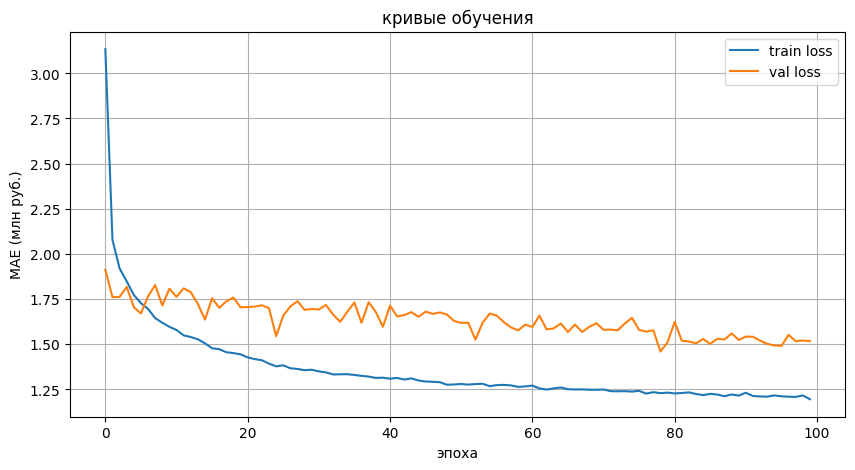

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('эпоха')
plt.ylabel('MAE (млн руб.)')
plt.title('кривые обучения')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
final_train = history.history['loss'][-1]
final_val = history.history['val_loss'][-1]
min_val = min(history.history['val_loss'])

print(f"финальный train loss: {final_train:.3f}")
print(f"финальный val loss:   {final_val:.3f}")
print(f"минимальный val loss: {min_val:.3f}")

if final_val > min_val * 1.05:
    print("признак переобучения: val_loss вырос относительно минимума")
else:
    print("сильного переобучения не наблюдается")

финальный train loss: 1.195
финальный val loss:   1.516
минимальный val loss: 1.459
сильного переобучения не наблюдается


Задание 6. Оценка на тестовой выборке

Считаем MAE и RMSE на test_data. Возвращаем предсказания к рублям (умножаем на 1e6). Строим residual plot: по оси X — предсказанная цена, по оси Y — остаток (реальная − предсказанная). Хорошая модель даёт облако остатков вокруг нуля без явного тренда.

In [18]:
y_pred_s = model.predict(X_test).flatten()
y_pred = y_pred_s * y_scale

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"MAE:  {mae:,.0f} руб.")
print(f"RMSE: {rmse:,.0f} руб.")

191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
MAE:  1,678,080 руб.
RMSE: 3,233,177 руб.


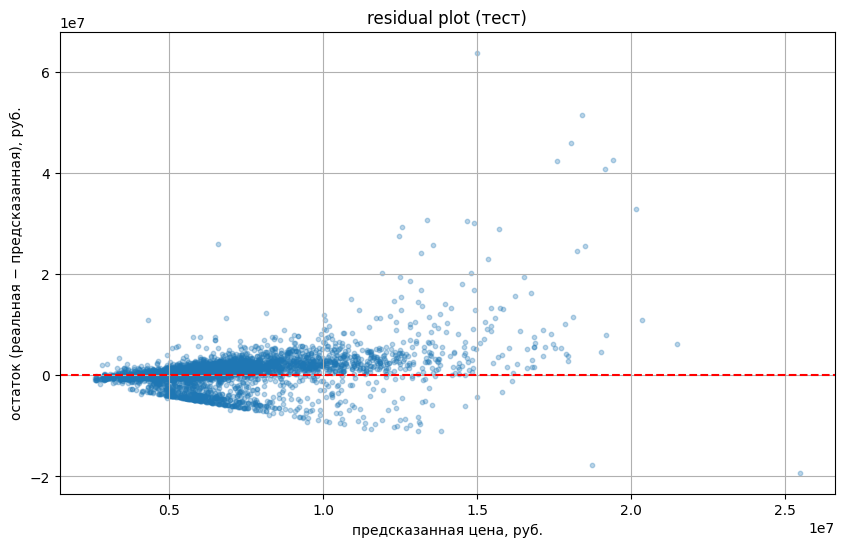

In [19]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.3, s=10)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('предсказанная цена, руб.')
plt.ylabel('остаток (реальная − предсказанная), руб.')
plt.title('residual plot (тест)')
plt.grid(True)
plt.show()

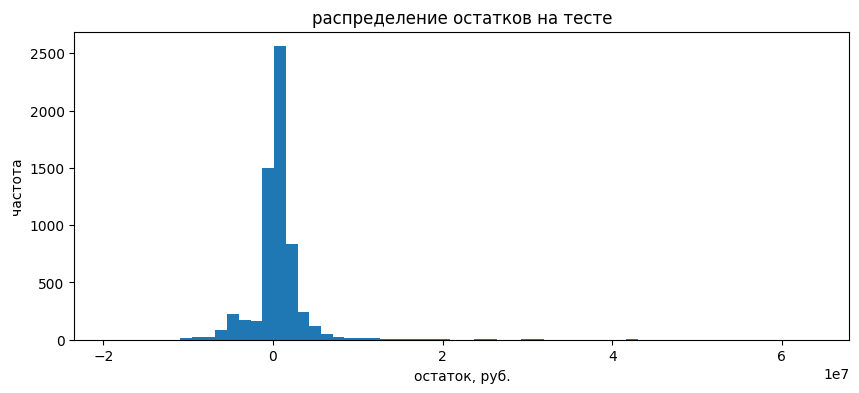

In [20]:
plt.figure(figsize=(10, 4))
plt.hist(residuals, bins=60)
plt.xlabel('остаток, руб.')
plt.ylabel('частота')
plt.title('распределение остатков на тесте')
plt.show()

Сколько данных сохранили (обоснование предобработки)

Проверяем, что после предобработки осталось разумное количество строк — важно, чтобы не «выкинуть» половину данных.

In [21]:
total_train_part = train_data.shape[0] + test_data.shape[0]
print("исходный train.csv:", train.shape[0], "строк")
print("после 80/20 всего:", total_train_part, "строк")
print("обучающая часть после предобработки:", train_data.shape[0], "строк")
print(f"доля сохранённых данных: {train_data.shape[0] / train.shape[0] * 100:.1f}%")

исходный train.csv: 30471 строк
после 80/20 всего: 29827 строк
обучающая часть после предобработки: 23732 строк
доля сохранённых данных: 77.9%
